# Descriptive statistics of existing performance evidence

## Module 1. Pipeline runtime distribution

**Question.** Across the recorded profiling runs, how is elapsed time distributed over the 25 candidate pipelines, over the seven trajectory steps, and over the runs themselves?

**Scope.** This notebook reads only `elapsed_time_sec` and `start_time_absolute` from the existing profile JSON files. It does not replay pipelines, run profilers, or re-fit models. Every number below is a descriptive summary of recorded observations.

**Unit of observation.** One profile file is one candidate pipeline executed once in one run. The expected design is 10 runs x 25 candidates = 250 observations.

**What this module does not do.** No significance tests, no confidence intervals, no causal attribution, and no stability thresholds. Differences between candidates are described, not explained: a slower candidate is not thereby shown to be slower for a particular reason.

**Reading order.** Each unit states its question and method, shows one small computation, and then states what the output does and does not support.

### 2.1. Environment and plotting conventions

Import the libraries and fix plotting defaults. No evidence file is read in this cell. Step colours are defined once here so that every figure uses the same colour for the same trajectory step.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import re
import tempfile
import numpy as np
import pandas as pd
import matplotlib
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'deai-matplotlib'))
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')

pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9})
STEP_COLORS = {1: '#4c72b0', 2: '#55a868', 3: '#c44e52', 4: '#8172b2',
               5: '#937860', 6: '#da8bc3', 7: '#8c8c8c'}

### 2.2. Paths and input source

Resolve the workspace, the trajectory manifest, the profile directory and the output directory, and print them. The profiles are not stored inside this workspace, so the notebook points at an explicit absolute path. If that path is wrong the notebook stops instead of searching for another copy: silently switching the input source would invalidate every number below. Set `PROFILES_ROOT_OVERRIDE` to analyse a different copy deliberately.

In [2]:
root = Path.cwd().resolve()
trajectory = 'spaceship_titanic_students'
manifest_path = root / trajectory / 'trajectory.json'
output = root / 'results' / trajectory / 'descriptive_statistics' / 'runtime_distribution'

# Profiles live outside this workspace. Override deliberately; there is no automatic fallback.
PROFILES_ROOT_OVERRIDE = None
DEFAULT_PROFILES_ROOT = Path('/Users/tue/Documents/10_Projects/deai-pro/profiles')
profiles_root = Path(PROFILES_ROOT_OVERRIDE) if PROFILES_ROOT_OVERRIDE is not None else DEFAULT_PROFILES_ROOT
profiles_dir = profiles_root / trajectory

print(f'Workspace root : {root}')
print(f'Manifest       : {manifest_path}')
print(f'Profiles root  : {profiles_root}  [{"override" if PROFILES_ROOT_OVERRIDE is not None else "default"}]')
print(f'Profiles dir   : {profiles_dir}')
print(f'Output dir     : {output}')
assert manifest_path.is_file(), f'Missing trajectory manifest: {manifest_path}'
assert profiles_dir.is_dir(), (f'Missing profiles directory: {profiles_dir}. '
                               'Set PROFILES_ROOT_OVERRIDE to the directory that holds the run folders.')
figures, tables = {}, {}

Workspace root : /Users/tue/.codex/worktrees/b832/deai-pro
Manifest       : /Users/tue/.codex/worktrees/b832/deai-pro/spaceship_titanic_students/trajectory.json
Profiles root  : /Users/tue/Documents/10_Projects/deai-pro/profiles  [default]
Profiles dir   : /Users/tue/Documents/10_Projects/deai-pro/profiles/spaceship_titanic_students
Output dir     : /Users/tue/.codex/worktrees/b832/deai-pro/results/spaceship_titanic_students/descriptive_statistics/runtime_distribution


**Output.** The resolved paths and the plotting conventions. **Limitation.** Printing a path shows which directory was requested; it does not prove that the files inside it are the ones that produced earlier results. That is what the fingerprints in unit 12 are for.

### 3.1. Candidate inventory from the manifest

Read the trajectory manifest and build the candidate list: pipeline identifier, step number, step name and manifest order. Manifest order is kept because it is the documented tie-break for the within-run Top 5 count in unit 9.

In [3]:
manifest = json.loads(manifest_path.read_text())
candidates = pd.DataFrame([
    dict(pipeline_id=Path(p['file']).stem, step=int(s['step']), step_name=s['name'], manifest_order=i)
    for i, (s, p) in enumerate((s, p) for s in manifest['steps'] for p in s['pipelines'])
])
assert candidates.pipeline_id.is_unique, 'Duplicate pipeline identifier in the manifest'
step_names = candidates.drop_duplicates('step').set_index('step').step_name.to_dict()
display(candidates.groupby(['step', 'step_name'], sort=True)
        .agg(candidates=('pipeline_id', 'size'), first=('pipeline_id', 'first'), last=('pipeline_id', 'last'))
        .reset_index())
print(f'{len(candidates)} candidates in {len(step_names)} steps')

,step,step_name,candidates,first,last
0,1,Linear baselines,3,pipeline_1_1,pipeline_1_3
1,2,Domain feature additions,3,pipeline_2_1,pipeline_2_3
2,3,Feature ablations,3,pipeline_3_1,pipeline_3_3
3,4,CPU histogram boosting,5,pipeline_4_1,pipeline_4_5
4,5,CPU random forests,4,pipeline_5_1,pipeline_5_4
5,6,Fixed probability blends,4,pipeline_6_1,pipeline_6_4
6,7,Decision threshold sensitivity,3,pipeline_7_1,pipeline_7_3


25 candidates in 7 steps


### 3.2. Run directories and expected profile files

Discover the run directories and build the expected 10 x 25 file grid. Report how many expected files exist per run, and list any JSON file that is not part of the manifest.

In [4]:
RUN_PATTERN = re.compile(r'run_\d+')
run_dirs = sorted((p for p in profiles_dir.iterdir() if p.is_dir() and RUN_PATTERN.fullmatch(p.name)),
                  key=lambda p: p.name)
run_ids = [p.name for p in run_dirs]
expected = pd.MultiIndex.from_product([run_ids, candidates.pipeline_id],
                                      names=['run_id', 'pipeline_id']).to_frame(index=False)
expected['path'] = [profiles_dir / r / f'{p}.json' for r, p in zip(expected.run_id, expected.pipeline_id)]
expected['present'] = [p.is_file() for p in expected.path]
known = set(candidates.pipeline_id)
unexpected = sorted(str(p.relative_to(profiles_dir)) for d in run_dirs for p in d.glob('*.json')
                    if p.stem not in known)
print(f'{len(run_dirs)} run directories, {len(candidates)} candidates, {len(expected)} expected profiles')
print(f'Unexpected JSON files outside the manifest: {len(unexpected)}')
display(expected.groupby('run_id').agg(expected=('path', 'size'), present=('present', 'sum'))
        .assign(missing=lambda d: d.expected - d.present))

10 run directories, 25 candidates, 250 expected profiles
Unexpected JSON files outside the manifest: 0


,expected,present,missing
run_id,,,
run_01,25,25,0
run_02,25,25,0
run_03,25,25,0
run_04,25,25,0
run_05,25,25,0
run_06,25,25,0
run_07,25,25,0
run_08,25,25,0
run_09,25,25,0


**Output.** 25 candidates in seven steps (3, 3, 3, 5, 4, 4 and 3 candidates) and the expected file grid. **Limitation.** The manifest defines what should exist, not what does. Presence is checked in unit 4.

### 4.1. Long observation table

Read every expected profile once and build one row per (run, candidate) with `run_id`, `pipeline_id`, `step`, `step_name`, `elapsed_sec`, `start_time_absolute` and `source_path`. A file is rejected only for a concrete reason: missing, unparsable JSON, or an `elapsed_time_sec` that is not a finite positive number. Rejected files are recorded, never filled in.

In [5]:
LONG_COLUMNS = ['run_id', 'pipeline_id', 'step', 'step_name', 'elapsed_sec', 'start_time_absolute', 'source_path']

def load_profiles(profiles_dir, candidates, run_ids=None):
    """Read every expected profile once; return (long table, issues, expected grid)."""
    profiles_dir = Path(profiles_dir)
    if run_ids is None:
        run_ids = sorted(p.name for p in profiles_dir.iterdir()
                         if p.is_dir() and RUN_PATTERN.fullmatch(p.name))
    grid = pd.MultiIndex.from_product([list(run_ids), candidates.pipeline_id],
                                      names=['run_id', 'pipeline_id']).to_frame(index=False)
    grid['path'] = [profiles_dir / r / f'{p}.json' for r, p in zip(grid.run_id, grid.pipeline_id)]
    records, issues = [], []
    for row in grid.itertuples(index=False):
        if not row.path.is_file():
            issues.append(dict(run_id=row.run_id, pipeline_id=row.pipeline_id,
                               issue='missing_file', detail=str(row.path)))
            continue
        try:
            payload = json.loads(row.path.read_text())
        except (OSError, ValueError) as exc:
            issues.append(dict(run_id=row.run_id, pipeline_id=row.pipeline_id,
                               issue='corrupt_json', detail=type(exc).__name__))
            continue
        elapsed = payload.get('elapsed_time_sec')
        if isinstance(elapsed, bool) or not isinstance(elapsed, (int, float)) \
                or not np.isfinite(elapsed) or elapsed <= 0:
            issues.append(dict(run_id=row.run_id, pipeline_id=row.pipeline_id,
                               issue='invalid_elapsed', detail=repr(elapsed)))
            continue
        records.append(dict(run_id=row.run_id, pipeline_id=row.pipeline_id, elapsed_sec=float(elapsed),
                            start_time_absolute=payload.get('start_time_absolute'),
                            source_path=str(row.path)))
    long = pd.DataFrame(records, columns=['run_id', 'pipeline_id', 'elapsed_sec',
                                          'start_time_absolute', 'source_path'])
    long = long.merge(candidates[['pipeline_id', 'step', 'step_name']], on='pipeline_id', how='left')
    if long.empty:
        long['start_time_absolute'] = pd.Series(pd.NaT, index=long.index, dtype='datetime64[ns, UTC]')
    else:
        long['start_time_absolute'] = pd.to_datetime(long['start_time_absolute'], unit='s', utc=True)
    issues = pd.DataFrame(issues, columns=['run_id', 'pipeline_id', 'issue', 'detail'])
    return long[LONG_COLUMNS], issues, grid

long, issues, expected = load_profiles(profiles_dir, candidates, run_ids)
assert not long.duplicated(['run_id', 'pipeline_id']).any(), 'Duplicate (run_id, pipeline_id) key'
print(f'{len(long)} valid observations from {len(expected)} expected profiles')
display(long.head())
display(long.dtypes.astype(str).to_frame('dtype'))

250 valid observations from 250 expected profiles


,run_id,pipeline_id,step,step_name,elapsed_sec,start_time_absolute,source_path
0,run_01,pipeline_1_1,1,Linear baselines,2.013027,2026-11-03 13:10:42.624364138+00:00,/Users/tue/Documents/10_Projects/deai-pro/profiles/space...
1,run_01,pipeline_1_2,1,Linear baselines,2.294819,2026-11-03 13:10:45.081645966+00:00,/Users/tue/Documents/10_Projects/deai-pro/profiles/space...
2,run_01,pipeline_1_3,1,Linear baselines,1.776667,2026-11-03 13:10:47.803539038+00:00,/Users/tue/Documents/10_Projects/deai-pro/profiles/space...
3,run_01,pipeline_2_1,2,Domain feature additions,2.568202,2026-11-03 13:10:50.009022951+00:00,/Users/tue/Documents/10_Projects/deai-pro/profiles/space...
4,run_01,pipeline_2_2,2,Domain feature additions,2.171228,2026-11-03 13:10:52.994255066+00:00,/Users/tue/Documents/10_Projects/deai-pro/profiles/space...


,dtype
run_id,str
pipeline_id,str
step,int64
step_name,str
elapsed_sec,float64
start_time_absolute,"datetime64[ns, UTC]"
source_path,str


### 4.2. Coverage matrix and data-quality report

Cross-tabulate candidates against runs to show which observations exist, then list every rejected file with its reason. A run counts as complete only when all 25 candidates have exactly one valid observation. No zero-filling or imputation is applied anywhere in this notebook.

In [6]:
coverage = (long.pivot_table(index='pipeline_id', columns='run_id', values='elapsed_sec', aggfunc='count')
            .reindex(index=candidates.pipeline_id, columns=run_ids).fillna(0).astype(int))

def complete_run_ids(coverage):
    """Runs in which every candidate has exactly one valid observation."""
    return [r for r in coverage.columns if len(coverage) and (coverage[r] == 1).all()]

def require_complete_runs(complete_runs):
    """Stop the notebook when no run is complete: cross-candidate comparisons would be invalid."""
    if not complete_runs:
        raise RuntimeError('No complete run: cross-candidate shares, ranks and step comparisons are skipped. '
                           'Single-candidate statistics above remain valid.')
    return list(complete_runs)

complete_runs = complete_run_ids(coverage)
quality_summary = pd.DataFrame([
    dict(check='expected_profiles', count=len(expected)),
    dict(check='valid_observations', count=len(long)),
    dict(check='missing_file', count=int((issues.issue == 'missing_file').sum())),
    dict(check='corrupt_json', count=int((issues.issue == 'corrupt_json').sum())),
    dict(check='invalid_elapsed', count=int((issues.issue == 'invalid_elapsed').sum())),
    dict(check='duplicate_keys', count=int(long.duplicated(['run_id', 'pipeline_id']).sum())),
    dict(check='unexpected_candidate_files', count=len(unexpected)),
    dict(check='missing_start_time', count=int(long.start_time_absolute.isna().sum())),
    dict(check='complete_runs', count=len(complete_runs)),
])
display(coverage)
display(quality_summary)
display(issues if len(issues) else pd.DataFrame({'issue': ['none recorded']}))
print(f'Complete runs used for cross-candidate comparisons: {len(complete_runs)} of {len(run_ids)}')

run_id,run_01,run_02,run_03,run_04,run_05,run_06,run_07,run_08,run_09,run_10
pipeline_id,,,,,,,,,,
pipeline_1_1,1,1,1,1,1,1,1,1,1,1
pipeline_1_2,1,1,1,1,1,1,1,1,1,1
pipeline_1_3,1,1,1,1,1,1,1,1,1,1
pipeline_2_1,1,1,1,1,1,1,1,1,1,1
pipeline_2_2,1,1,1,1,1,1,1,1,1,1
pipeline_2_3,1,1,1,1,1,1,1,1,1,1
pipeline_3_1,1,1,1,1,1,1,1,1,1,1
pipeline_3_2,1,1,1,1,1,1,1,1,1,1
pipeline_3_3,1,1,1,1,1,1,1,1,1,1


,check,count
0,expected_profiles,250
1,valid_observations,250
2,missing_file,0
3,corrupt_json,0
4,invalid_elapsed,0
5,duplicate_keys,0
6,unexpected_candidate_files,0
7,missing_start_time,0
8,complete_runs,10


,issue
0,none recorded


Complete runs used for cross-candidate comparisons: 10 of 10


**Output.** 250 valid observations, 25 candidates, 10 runs, no rejected files, and a fully populated 10 x 25 coverage matrix. **Limitation.** A complete matrix means every expected file parsed and carried a finite positive `elapsed_time_sec`. It does not validate the profiler, the pipeline code, or whether the recorded time covers the same work in every run.

### 5.1. Per-run totals and timestamps

Aggregate the long table per run: observation count, candidate count, total elapsed time, first and last start timestamp, and the wall-clock span. Totals are computed by summing the 25 recorded values of each run, not by summing candidate medians.

In [7]:
run_summary = (long.groupby('run_id')
               .agg(observations=('elapsed_sec', 'size'), candidates=('pipeline_id', 'nunique'),
                    total_elapsed_sec=('elapsed_sec', 'sum'),
                    first_start=('start_time_absolute', 'min'),
                    last_start=('start_time_absolute', 'max')))
run_summary['span_min'] = (run_summary.last_start - run_summary.first_start).dt.total_seconds() / 60
run_summary['mean_candidate_sec'] = run_summary.total_elapsed_sec / run_summary.candidates
run_summary['complete'] = run_summary.index.isin(complete_runs)
run_display = run_summary.copy()
run_display['first_start'] = run_display.first_start.dt.strftime('%Y-%m-%d %H:%M:%S')
run_display['last_start'] = run_display.last_start.dt.strftime('%Y-%m-%d %H:%M:%S')
display(run_display.round(3))
print(f'Median of per-run totals: {run_summary.total_elapsed_sec.median():.3f} s')
print(f'Run totals: min {run_summary.total_elapsed_sec.min():.3f} s, '
      f'max {run_summary.total_elapsed_sec.max():.3f} s')

,observations,candidates,total_elapsed_sec,first_start,last_start,span_min,mean_candidate_sec,complete
run_id,,,,,,,,
run_01,25,25,75.071,2026-11-03 13:10:42,2026-11-03 13:12:04,1.359,3.003,True
run_02,25,25,80.581,2026-11-05 15:42:31,2026-11-05 15:44:00,1.485,3.223,True
run_03,25,25,82.020,2026-11-05 15:44:07,2026-11-05 15:45:38,1.512,3.281,True
run_04,25,25,79.305,2026-11-05 15:45:44,2026-11-05 15:47:12,1.470,3.172,True
run_05,25,25,78.856,2026-11-05 15:47:17,2026-11-05 15:48:44,1.457,3.154,True
run_06,25,25,77.675,2026-11-05 15:48:50,2026-11-05 15:50:16,1.433,3.107,True
run_07,25,25,79.335,2026-11-05 15:50:21,2026-11-05 15:51:49,1.468,3.173,True
run_08,25,25,79.959,2026-11-05 15:51:54,2026-11-05 15:53:23,1.476,3.198,True
run_09,25,25,76.941,2026-11-05 15:53:28,2026-11-05 15:54:54,1.429,3.078,True


Median of per-run totals: 79.080 s
Run totals: min 75.071 s, max 82.020 s


### 5.2. Run totals over execution order

Plot the per-run total against execution order. The dashed line marks the median of the run totals. This shows how much the whole run moves between repetitions before any candidate-level comparison is made.

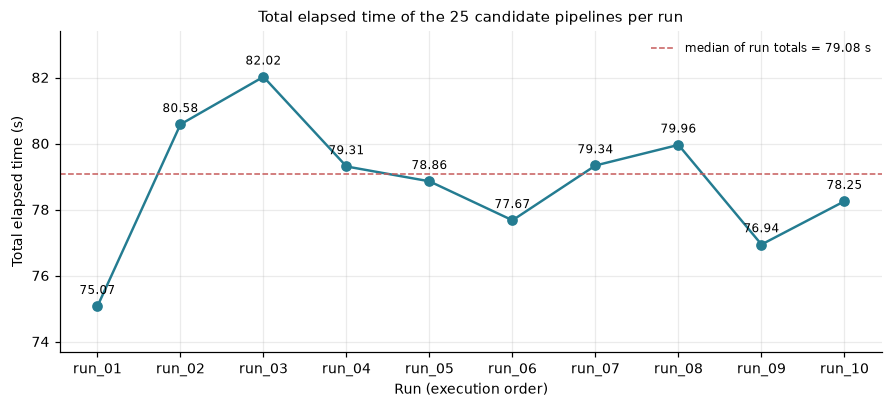

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
ax.plot(run_summary.index, run_summary.total_elapsed_sec, marker='o', color='#247c91', lw=1.6)
for x, y in zip(run_summary.index, run_summary.total_elapsed_sec):
    ax.annotate(f'{y:.2f}', (x, y), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
ax.axhline(run_summary.total_elapsed_sec.median(), color='#c65b5b', ls='--', lw=1,
           label=f'median of run totals = {run_summary.total_elapsed_sec.median():.2f} s')
ax.set_xlabel('Run (execution order)')
ax.set_ylabel('Total elapsed time (s)')
ax.set_title('Total elapsed time of the 25 candidate pipelines per run')
ax.legend(frameon=False, fontsize=8)
ax.margins(y=0.20)
figures['run_total_elapsed'] = fig
plt.show()

**Output.** Run totals range from 75.07 s (run_01) to 82.02 s (run_03) with a median of 79.08 s; the largest total is 1.09x the smallest and the CV of run totals is 0.025. Each run's 25 profiles start within about 1.4-1.5 minutes. **Limitation.** 75.07 s describes run_01 only and is not a module-wide baseline. A run total is a sum of recorded profile times, so it inherits whatever the profiler includes and excludes. The spread across runs is described, not explained.

### 6. Per-candidate descriptive statistics

For each candidate compute n, median, mean, sample standard deviation (`ddof=1`), Q1, Q3, IQR, minimum, maximum and the coefficient of variation (std / mean). Quantiles use linear interpolation. Candidates are sorted by median, descending. CV is reported as an auxiliary dispersion measure only; no threshold is used to label a candidate stable or unstable.

In [9]:
def summarize_candidates(long):
    grouped = long.groupby('pipeline_id')['elapsed_sec']
    stats = pd.DataFrame({'n': grouped.size(), 'median': grouped.median(), 'mean': grouped.mean(),
                          'std': grouped.std(ddof=1), 'q1': grouped.quantile(0.25),
                          'q3': grouped.quantile(0.75), 'min': grouped.min(), 'max': grouped.max()})
    stats['iqr'] = stats.q3 - stats.q1
    stats['cv'] = stats['std'] / stats['mean']
    return stats

candidate_stats = (summarize_candidates(long)
                   .join(candidates.set_index('pipeline_id')[['step', 'step_name']])
                   .sort_values(['median', 'pipeline_id'], ascending=[False, True]))
candidate_stats['median_rank'] = np.arange(1, len(candidate_stats) + 1)
display(candidate_stats.round(3))
med = candidate_stats['median']
print(f'Median range: {med.min():.3f} s to {med.max():.3f} s (ratio {med.max() / med.min():.2f})')

,n,median,mean,std,q1,q3,min,max,iqr,cv,step,step_name,median_rank
pipeline_id,,,,,,,,,,,,,
pipeline_7_2,10,4.766,4.723,0.238,4.638,4.830,4.193,5.111,0.192,0.050,7,Decision threshold sensitivity,1
pipeline_7_1,10,4.576,4.752,0.415,4.491,5.098,4.237,5.486,0.607,0.087,7,Decision threshold sensitivity,2
pipeline_7_3,10,4.554,4.583,0.166,4.470,4.650,4.362,4.894,0.180,0.036,7,Decision threshold sensitivity,3
pipeline_6_3,10,4.449,4.640,0.662,4.407,4.511,4.289,6.508,0.104,0.143,6,Fixed probability blends,4
pipeline_6_1,10,4.437,4.480,0.252,4.345,4.477,4.170,5.025,0.132,0.056,6,Fixed probability blends,5
pipeline_6_2,10,4.363,4.404,0.213,4.309,4.442,4.176,4.899,0.133,0.048,6,Fixed probability blends,6
pipeline_5_3,10,4.096,4.130,0.162,4.033,4.146,3.988,4.528,0.114,0.039,5,CPU random forests,7
pipeline_6_4,10,3.828,3.840,0.256,3.635,3.975,3.550,4.251,0.340,0.067,6,Fixed probability blends,8
pipeline_5_2,10,3.747,3.704,0.277,3.464,3.919,3.263,4.104,0.454,0.075,5,CPU random forests,9


Median range: 1.994 s to 4.766 s (ratio 2.39)


**Output.** Candidate medians span 1.994 s (pipeline_3_3) to 4.766 s (pipeline_7_2), a 2.39x range. The six highest medians all belong to steps 6 and 7 (fixed probability blends and decision threshold sensitivity); the lowest belong to steps 1-3. **Limitation.** A median of ten observations is coarse: one slow run can move a candidate by a rank. The ordering describes recorded cost, not algorithmic quality.

### 7. Candidate comparison

Horizontal boxplots of the ten observations per candidate, sorted by median with the most expensive candidate at the top. Each box spans Q1-Q3 with the median drawn as a line; whiskers extend to the most extreme observation within 1.5 x IQR of the box, and every individual observation is drawn on top. Flier symbols are disabled because the raw points already show all values. Boxes are coloured by trajectory step.

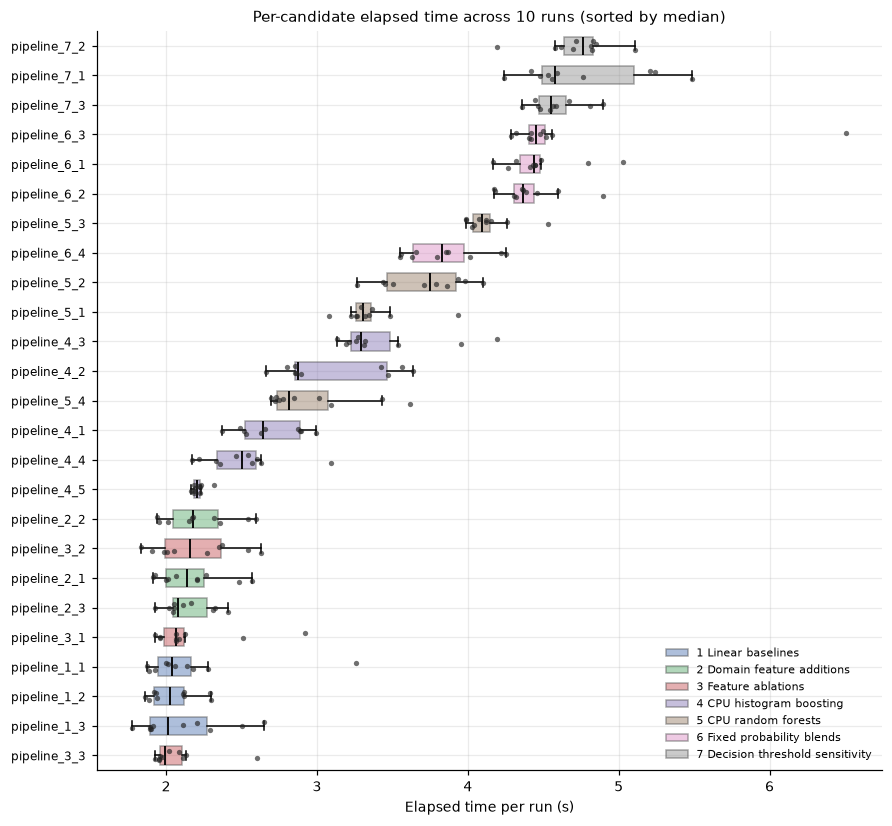

In [10]:
order = candidate_stats.index.tolist()
data = [long.loc[long.pipeline_id == p, 'elapsed_sec'].to_numpy() for p in order]
fig, ax = plt.subplots(figsize=(8, 7.4), layout='constrained')
bp = ax.boxplot(data, orientation='horizontal', patch_artist=True, showfliers=False, whis=1.5,
                widths=0.62, medianprops=dict(color='black', lw=1.2))
for patch, p in zip(bp['boxes'], order):
    patch.set_facecolor(STEP_COLORS[candidate_stats.loc[p, 'step']])
    patch.set_alpha(0.45)
    patch.set_edgecolor('#444444')
rng = np.random.default_rng(0)
for y, p in enumerate(order, start=1):
    vals = long.loc[long.pipeline_id == p, 'elapsed_sec'].to_numpy()
    ax.scatter(vals, y + rng.uniform(-0.16, 0.16, len(vals)), s=12, color='#222222',
               alpha=0.65, zorder=3, linewidths=0)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Elapsed time per run (s)')
ax.set_title('Per-candidate elapsed time across 10 runs (sorted by median)')
handles = [Patch(facecolor=STEP_COLORS[s], alpha=0.45, edgecolor='#444444',
                 label=f'{s} {step_names[s]}') for s in sorted(step_names)]
ax.legend(handles=handles, frameon=False, fontsize=7, loc='lower right')
figures['candidate_elapsed_boxplot'] = fig
plt.show()

**Output.** The clearest separation is between the step 6-7 group (medians 4.36-4.77 s) and the step 1-3 group (1.99-2.18 s): that gap is far wider than any box. Inside each group the boxes overlap for several neighbouring pairs (pipeline_7_2 with 7_1, pipeline_6_1 with 6_2, pipeline_5_1 with 4_3), and the overlaid points show that the ordering is not produced by a single extreme run. **Limitation.** Where boxes overlap, ten runs do not resolve the order of neighbouring candidates. The figure shows that overlap; it does not test it.

### 8.1. Variability ranking

Rank candidates by CV and add the ratio of the largest and smallest observation to the candidate median. This separates candidates whose typical cost is high from candidates whose cost moves a lot between runs.

In [11]:
variability = candidate_stats[['step', 'step_name', 'n', 'median', 'iqr', 'std', 'cv', 'min', 'max']].copy()
variability['max_over_median'] = candidate_stats['max'] / candidate_stats['median']
variability['min_over_median'] = candidate_stats['min'] / candidate_stats['median']
variability = variability.sort_values('cv', ascending=False)
display(variability.round(3))
run_cv = run_summary.total_elapsed_sec.std(ddof=1) / run_summary.total_elapsed_sec.mean()
print(f'Run-total CV: {run_cv:.4f}; max/min run total: '
      f'{run_summary.total_elapsed_sec.max() / run_summary.total_elapsed_sec.min():.3f}')

,step,step_name,n,median,iqr,std,cv,min,max,max_over_median,min_over_median
pipeline_id,,,,,,,,,,,
pipeline_1_1,1,Linear baselines,10,2.037,0.222,0.407,0.188,1.873,3.258,1.600,0.920
pipeline_3_1,3,Feature ablations,10,2.066,0.131,0.311,0.144,1.926,2.921,1.414,0.932
pipeline_6_3,6,Fixed probability blends,10,4.449,0.104,0.662,0.143,4.289,6.508,1.463,0.964
pipeline_1_3,1,Linear baselines,10,2.013,0.375,0.293,0.139,1.777,2.649,1.316,0.883
pipeline_3_2,3,Feature ablations,10,2.161,0.374,0.275,0.125,1.834,2.630,1.217,0.849
pipeline_4_2,4,CPU histogram boosting,10,2.877,0.607,0.373,0.120,2.660,3.640,1.265,0.924
pipeline_5_4,5,CPU random forests,10,2.812,0.337,0.325,0.109,2.692,3.618,1.287,0.957
pipeline_4_4,4,CPU histogram boosting,10,2.502,0.255,0.262,0.105,2.172,3.091,1.235,0.868
pipeline_2_1,2,Domain feature additions,10,2.138,0.248,0.226,0.104,1.915,2.568,1.201,0.896


Run-total CV: 0.0248; max/min run total: 1.093


### 8.2. Candidate x run ratio heatmap

Divide each observation by that candidate's own median across runs. The result is unitless: 1.0 means the run matched the candidate's typical cost, 1.2 means 20% above it. Rows follow the pipeline index order of the trajectory manifest (step, then pipeline within step), so the heatmap lines up with the experiment inventory; columns follow execution order. The colour scale is centred on 1.0.

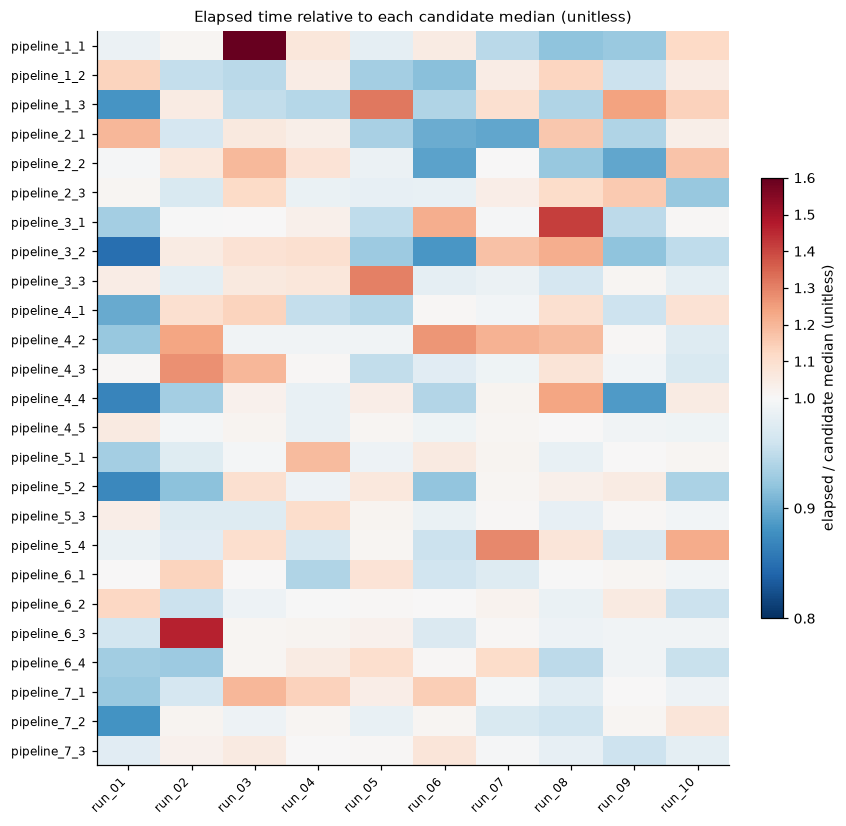

Ratio range: 0.849 to 1.600; 8 of 250 values above 1.25, 0 below 0.75


In [12]:
index_order = candidates.sort_values('manifest_order').pipeline_id.tolist()
pivot = (long.pivot(index='pipeline_id', columns='run_id', values='elapsed_sec')
         .reindex(index=index_order, columns=run_ids))
ratio = pivot.div(pivot.median(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7.6, 7.4), layout='constrained')
im = ax.imshow(ratio.to_numpy(), aspect='auto', cmap='RdBu_r',
               norm=TwoSlopeNorm(vcenter=1.0, vmin=0.8, vmax=1.6))
ax.set_xticks(range(len(run_ids)))
ax.set_xticklabels(run_ids, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(index_order)))
ax.set_yticklabels(index_order, fontsize=8)
ax.set_title('Elapsed time relative to each candidate median (unitless)')
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.6)
cb.set_label('elapsed / candidate median (unitless)')
figures['candidate_run_ratio_heatmap'] = fig
plt.show()
print(f'Ratio range: {ratio.min().min():.3f} to {ratio.max().max():.3f}; '
      f'{(ratio > 1.25).to_numpy().sum()} of {ratio.notna().to_numpy().sum()} values above 1.25, '
      f'{(ratio < 0.75).to_numpy().sum()} below 0.75')

**Output.** CV ranges from 0.020 (pipeline_4_5) to 0.188 (pipeline_1_1). Four of the five highest CVs belong to steps 1 and 3 (pipeline_1_1 0.188, pipeline_3_1 0.144, pipeline_1_3 0.139, pipeline_3_2 0.125), while the expensive step 6-7 candidates sit in the lower half of the CV ranking, with pipeline_6_3 as the exception at 0.143. 8 of 250 observations exceed 1.25x their candidate median and none fall below 0.75x; the largest ratio is 1.60 (pipeline_1_1 in run_03). **Limitation.** A high CV on a cheap candidate is a small absolute change. The heatmap shows where excursions sit but cannot say whether they come from the candidate, the run, or the measurement.

### 9.1. Within-run cost shares and Top 5 frequency

Compute each candidate's share of its own run total first, then average those shares across complete runs. Shares are additive within a run, so the mean shares sum to 100%. Also report the fixed Top 5 (the five candidates with the highest cross-run median) and, separately, how often each candidate entered a run's own Top 5, with ties broken by manifest order.

In [13]:
complete_runs = require_complete_runs(complete_runs)
complete_long = long[long.run_id.isin(complete_runs)]
run_totals = complete_long.groupby('run_id')['elapsed_sec'].sum()
share = (complete_long.pivot(index='pipeline_id', columns='run_id', values='elapsed_sec')
         .reindex(index=candidates.pipeline_id, columns=complete_runs).div(run_totals, axis=1) * 100)
manifest_rank = {p: i for i, p in enumerate(candidates.pipeline_id)}

def within_run_top5(column):
    return sorted(column.index, key=lambda p: (-column[p], manifest_rank[p]))[:5]

top5_counts = pd.Series({p: sum(p in within_run_top5(share[r]) for r in complete_runs)
                         for p in candidates.pipeline_id})
fixed_top5 = candidate_stats.index[:5].tolist()
concentration = pd.DataFrame({
    'step': candidates.set_index('pipeline_id').step,
    'mean_share_pct': share.mean(axis=1),
    'median_share_pct': share.median(axis=1),
    'top5_count': top5_counts,
    'in_fixed_top5': [p in fixed_top5 for p in share.index],
}).sort_values('mean_share_pct', ascending=False)
fixed_top5_share = share.loc[fixed_top5].sum()
display(concentration.round(2))
display(fixed_top5_share.round(2).to_frame('fixed_top5_share_pct'))
print(f'Fixed Top 5: {", ".join(fixed_top5)}')
print(f'Runs included: {len(complete_runs)}')

,step,mean_share_pct,median_share_pct,top5_count,in_fixed_top5
pipeline_7_1,7,6.03,5.88,9,True
pipeline_7_2,7,6.00,5.99,9,True
pipeline_6_3,6,5.88,5.67,10,True
pipeline_7_3,7,5.82,5.78,9,True
pipeline_6_1,6,5.69,5.59,7,True
pipeline_6_2,6,5.60,5.53,4,False
pipeline_5_3,5,5.25,5.21,2,False
pipeline_6_4,6,4.87,4.84,0,False
pipeline_5_2,5,4.70,4.72,0,False
pipeline_4_3,4,4.36,4.21,0,False


,fixed_top5_share_pct
run_id,
run_01,28.78
run_02,31.61
run_03,29.21
run_04,29.37
run_05,29.67
run_06,30.31
run_07,28.39
run_08,27.98
run_09,29.47


Fixed Top 5: pipeline_7_2, pipeline_7_1, pipeline_7_3, pipeline_6_3, pipeline_6_1
Runs included: 10


### 9.2. Mean share ranking and cumulative concentration

Rank candidates by mean within-run share and plot the cumulative share. The cumulative curve answers how much of a typical run the most expensive candidates account for, without assuming that the ranking is identical in every run.

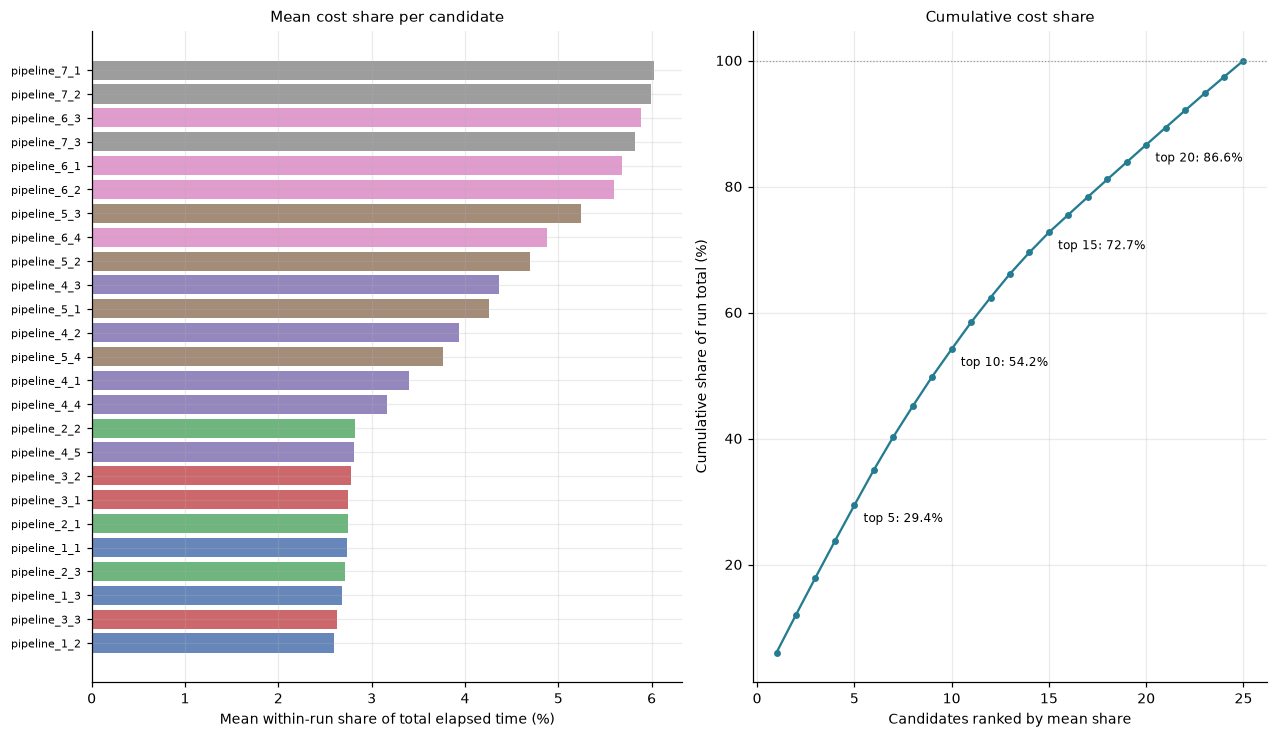

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.6), layout='constrained',
                         gridspec_kw={'width_ratios': [1.15, 1]})
ranked = concentration.sort_values('mean_share_pct')
axes[0].barh(ranked.index, ranked.mean_share_pct,
             color=[STEP_COLORS[s] for s in ranked.step], alpha=0.85)
axes[0].set_xlabel('Mean within-run share of total elapsed time (%)')
axes[0].set_title('Mean cost share per candidate')
axes[0].tick_params(axis='y', labelsize=7)
cum = concentration.sort_values('mean_share_pct', ascending=False).mean_share_pct.cumsum()
axes[1].plot(range(1, len(cum) + 1), cum, marker='o', ms=3.5, color='#247c91')
axes[1].axhline(100, color='#999999', lw=0.8, ls=':')
for k in (5, 10, 15, 20):
    axes[1].annotate(f'top {k}: {cum.iloc[k - 1]:.1f}%', (k, cum.iloc[k - 1]),
                     textcoords='offset points', xytext=(6, -11), fontsize=8)
axes[1].set_xlabel('Candidates ranked by mean share')
axes[1].set_ylabel('Cumulative share of run total (%)')
axes[1].set_title('Cumulative cost share')
figures['cost_concentration'] = fig
plt.show()

**Output.** The fixed Top 5 accounts for 28.0-31.6% of each run's total (mean 29.4%). pipeline_6_3 is in the within-run Top 5 in all 10 runs, pipeline_7_1, 7_2 and 7_3 in 9, and pipeline_6_1 in 7. pipeline_6_2 enters 4 times and pipeline_5_3 twice. The boundary of the set is the least stable part: pipeline_6_1 leaves it in three runs (run_04, run_06, run_07), pipeline_7_3 in one (run_09), and run_01 drops both pipeline_7_2 and pipeline_7_1. **Limitation.** A 29% share for five of 25 candidates is a statement about recorded time, not evidence about where optimisation effort would pay off.

### 10.1. Step-level cost

Sum elapsed time per step within each complete run, then summarise across runs. Step totals must add up to the run total, and step shares must add up to 100% in every complete run. Candidate counts per step are shown because a step total depends on how many candidates it contains.

In [15]:
step_run = (complete_long.groupby(['step', 'run_id'])['elapsed_sec'].sum()
            .unstack().reindex(columns=complete_runs))
step_share = step_run.div(run_totals, axis=1) * 100
step_summary = pd.DataFrame({
    'step_name': [step_names[s] for s in step_run.index],
    'candidates': candidates.groupby('step').size(),
    'median_total_sec': step_run.median(axis=1),
    'mean_share_pct': step_share.mean(axis=1),
    'share_std_pp': step_share.std(axis=1),
    'share_min_pct': step_share.min(axis=1),
    'share_max_pct': step_share.max(axis=1),
})
display(step_run.round(2))
display(step_summary.round(2))
print(f'Runs included: {len(complete_runs)}')

run_id,run_01,run_02,run_03,run_04,run_05,run_06,run_07,run_08,run_09,run_10
step,,,,,,,,,,
1,6.08,6.10,7.09,6.20,6.54,5.89,6.25,6.05,6.33,6.68
2,6.85,6.41,7.18,6.62,6.20,5.92,6.26,6.80,6.37,6.68
3,5.85,6.29,6.53,6.63,6.56,6.38,6.57,7.48,5.96,6.09
4,12.85,15.18,14.61,13.31,13.30,14.05,14.13,15.16,13.11,13.68
5,13.37,13.40,14.47,14.89,14.25,13.67,14.89,14.16,14.10,14.36
6,17.19,19.26,17.13,17.06,17.96,16.81,17.51,16.77,17.30,16.66
7,12.88,13.94,15.01,14.61,14.05,14.96,13.72,13.54,13.77,14.11


,step_name,candidates,median_total_sec,mean_share_pct,share_std_pp,share_min_pct,share_max_pct
step,,,,,,,
1,Linear baselines,3,6.22,8.02,0.40,7.57,8.65
2,Domain feature additions,3,6.51,8.29,0.46,7.62,9.13
3,Feature ablations,3,6.46,8.16,0.49,7.75,9.35
4,CPU histogram boosting,5,13.87,17.68,0.77,16.79,18.95
5,CPU random forests,4,14.20,17.97,0.64,16.63,18.78
6,Fixed probability blends,4,17.16,22.04,0.97,20.88,23.90
7,Decision threshold sensitivity,3,14.00,17.84,0.71,16.93,19.26


Runs included: 10


### 10.2. Step cost distribution across runs

Boxplots of the ten per-run step totals, with the individual run values overlaid. Candidate counts are annotated on the axis labels. A step with more candidates is expected to cost more in total; this figure describes recorded cost, not per-candidate efficiency.

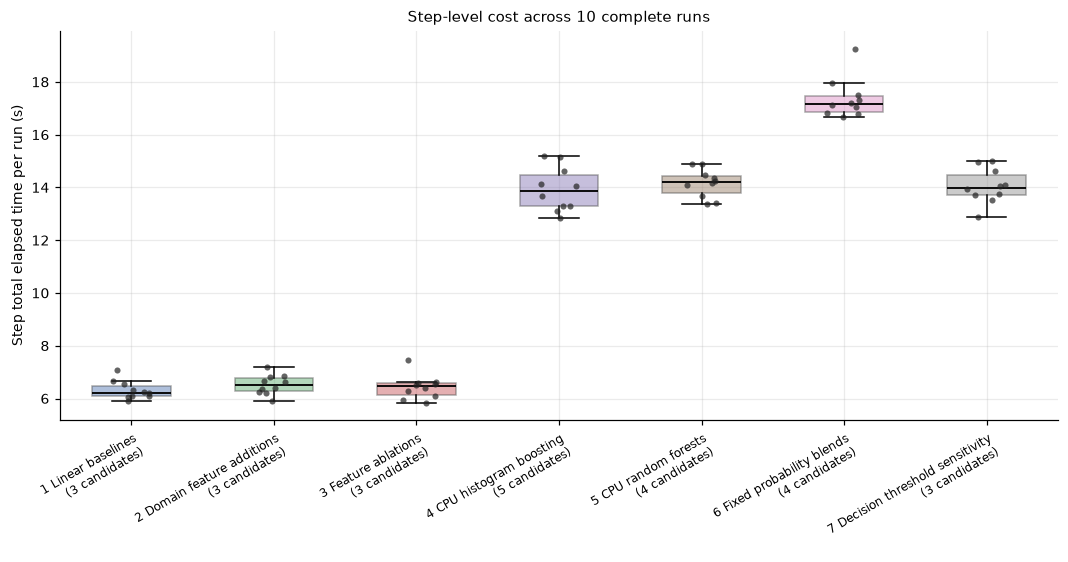

In [16]:
fig, ax = plt.subplots(figsize=(9.6, 5.0), layout='constrained')
step_data = [step_run.loc[s].to_numpy() for s in step_run.index]
bp = ax.boxplot(step_data, patch_artist=True, showfliers=False, whis=1.5, widths=0.55,
                medianprops=dict(color='black', lw=1.2))
for patch, s in zip(bp['boxes'], step_run.index):
    patch.set_facecolor(STEP_COLORS[s])
    patch.set_alpha(0.45)
    patch.set_edgecolor('#444444')
rng = np.random.default_rng(1)
for x, s in enumerate(step_run.index, start=1):
    vals = step_run.loc[s].to_numpy()
    ax.scatter(x + rng.uniform(-0.14, 0.14, len(vals)), vals, s=16, color='#222222',
               alpha=0.7, zorder=3, linewidths=0)
ax.set_xticks(range(1, len(step_run) + 1))
ax.set_xticklabels([f'{s} {step_names[s]}\n({int((candidates.step == s).sum())} candidates)'
                    for s in step_run.index], fontsize=8, rotation=30, ha='right',
                   rotation_mode='anchor')
ax.set_ylabel('Step total elapsed time per run (s)')
ax.set_title('Step-level cost across 10 complete runs')
figures['step_cost_boxplot'] = fig
plt.show()

**Output.** Step 6 (fixed probability blends, 4 candidates) carries the largest mean share at 22.0%, followed by steps 5, 7 and 4 at 18.0%, 17.8% and 17.7%; steps 1-3 each carry about 8%. Step shares vary little across runs (standard deviation at most 0.97 percentage points). **Limitation.** A step total mixes candidate count with per-candidate cost, so a large step total does not by itself mean its candidates are individually expensive.

### Reviewed interpretation of Module 1

Reviewed on 2026-11-05 after executing the notebook and inspecting its tables and chart images. This prose is assistant-written and is not regenerated on execution.

**Which candidates are usually the most expensive, and does the ordering hold across runs?**
The five highest cross-run medians are pipeline_7_2 (4.77 s), pipeline_7_1 (4.58 s), pipeline_7_3 (4.55 s), pipeline_6_3 (4.45 s) and pipeline_6_1 (4.44 s); the cheapest is pipeline_3_3 at 1.99 s, a 2.39x range. The ordering is broadly stable: the lowest Spearman rank correlation between any two runs is 0.84 (median 0.90), and the five highest-median candidates occupy three to five of every run's own Top 5 (three in run_01, four in four runs, five in five runs). The boundary of a single run's Top 5 is not stable: pipeline_6_1 is absent from three runs' Top 5 (run_04, run_06, run_07), pipeline_7_3 from one (run_09), and run_01 drops both pipeline_7_2 and pipeline_7_1, with pipeline_6_2 (4 runs) or pipeline_5_3 (2 runs) taking their place. The top of the ranking is a property of the candidate set; the fifth slot is not.

**Which candidates vary most, and is that accompanied by whole-run changes?**
CV ranges from 0.020 to 0.188. The most variable candidates are cheap ones (pipeline_1_1 at 0.188, pipeline_3_1 at 0.144, pipeline_1_3 at 0.139), and the expensive step 6-7 candidates are mostly among the least variable (pipeline_7_3 at 0.036, pipeline_5_3 at 0.039, pipeline_6_2 at 0.048), with pipeline_6_3 as the clear exception at 0.143. Only 8 of 250 observations exceed 1.25x their candidate median and none fall below 0.75x, so the dispersion is asymmetric: occasional slow repetitions rather than symmetric noise. Run totals move much less than individual candidates (CV 0.025, max/min 1.09), so candidate-level excursions do not accumulate into whole-run swings. The two slowest runs differ in kind. run_03 (82.02 s) is broadly slower: its median ratio to the candidate medians is 1.03 and 6 of 25 candidates sit above 1.10x, with pipeline_1_1 the extreme at 1.60x. run_02 (80.58 s) has a median ratio of 1.00 and is driven by a few candidates instead, the largest being pipeline_6_3 at 6.51 s (1.46x its median). Neither pattern is a uniform shift of all 25 candidates.

**Which steps persistently dominate cost?**
Step 6 (fixed probability blends) carries 22.0% of the mean run total from 4 of 25 candidates; steps 5, 7 and 4 carry 18.0%, 17.8% and 17.7% from 4, 3 and 5 candidates; steps 1-3 carry about 8% each from 3 candidates each. Step shares are stable across runs (standard deviation at most 0.97 percentage points), so this is a persistent pattern rather than a run-specific accident. The fixed Top 5 accounts for 28.0-31.6% of each run.

**What should be investigated next, and what cannot be determined here?**
The next step is to look inside the expensive steps: which internal stages of the step 6 blends and the step 7 threshold sweeps consume the recorded time, and whether the step 6 total is driven by one candidate or spread over all four. The occasional slow repetitions (pipeline_1_1 in run_03, pipeline_6_3 in run_02) justify a targeted look at those two profile files. This module cannot determine why any candidate is slow: it has no per-stage breakdown, no hardware or load metadata, and no repeated measurement under controlled conditions. It also cannot separate candidate cost from run-level effects, because each candidate is observed once per run and the design has no within-run replication. No significance test, confidence interval or causal claim is made, and none should be read into these numbers.

**Verification.** 250 observations, 25 candidates, 10 complete runs, n = 10 per candidate. Per-run totals were recomputed from the raw JSON and match. Candidate shares and step shares sum to 100% in every complete run, step totals equal run totals, and the mean and cumulative share arithmetic is consistent. Median, IQR, sample standard deviation and the sum-then-aggregate order were checked on small known data, and missing, corrupt, invalid-elapsed and no-complete-run cases were exercised explicitly.

### 12. Export, verification and review status

Verify the analysis before writing anything: row and coverage counts, per-run totals recomputed from the raw JSON, share arithmetic, and small known-data checks for median, IQR, sample standard deviation and the "sum per run, then aggregate" order. Then export the tables as CSV and the figures as PNG and SVG, and record fingerprints of the manifest and every profile file. The final line compares the current inputs and code against the reviewed snapshot stored in the notebook metadata; if either changed, the written interpretation must be reviewed again.

In [17]:
# --- design and coverage expectations
assert len(long) == 250, f'expected 250 observations, found {len(long)}'
assert long.pipeline_id.nunique() == 25, 'expected 25 candidates'
assert len(run_ids) == 10, f'expected 10 run directories, found {len(run_ids)}'
assert len(complete_runs) == 10, f'expected 10 complete runs, found {len(complete_runs)}'
assert (candidate_stats.n == 10).all(), 'every candidate must have 10 valid observations'
assert (coverage.to_numpy() == 1).all(), 'coverage matrix must be fully populated'

# --- per-run totals recomputed independently from the raw JSON
raw_totals = {}
for run in complete_runs:
    values = [json.loads((profiles_dir / run / f'{p}.json').read_text())['elapsed_time_sec']
              for p in candidates.pipeline_id]
    raw_totals[run] = float(np.sum(values))
assert np.allclose([raw_totals[r] for r in complete_runs],
                   run_totals.reindex(complete_runs).to_numpy(), rtol=0, atol=1e-9)

# --- 75.07 s belongs to run_01 only and is not a module-wide baseline
assert np.isclose(run_summary.loc['run_01', 'total_elapsed_sec'], 75.071, atol=5e-4)
assert not np.isclose(run_summary.total_elapsed_sec.median(),
                      run_summary.loc['run_01', 'total_elapsed_sec'])

# --- share arithmetic
assert np.allclose(share.sum(), 100.0), 'candidate shares must sum to 100% per run'
assert np.allclose(concentration.mean_share_pct.sum(), 100.0)
assert np.allclose(concentration.mean_share_pct, share.mean(axis=1).reindex(concentration.index))
assert np.allclose(fixed_top5_share.mean(), concentration.loc[fixed_top5, 'mean_share_pct'].sum())
assert np.allclose(step_share.sum(), 100.0), 'step shares must sum to 100% per run'
assert np.allclose(step_run.sum(), run_totals.reindex(complete_runs)), 'step totals must equal run totals'
assert np.allclose(step_summary.mean_share_pct.sum(), 100.0)
assert np.allclose(step_summary.mean_share_pct, step_share.mean(axis=1))
assert np.allclose(cum.iloc[-1], 100.0)

# --- unit checks on small known data
known = pd.Series([1.0, 2.0, 3.0, 4.0])
assert known.median() == 2.5
assert known.quantile(0.25) == 1.75 and known.quantile(0.75) == 3.25
assert np.isclose(known.quantile(0.75) - known.quantile(0.25), 1.5)
assert np.isclose(known.std(ddof=1), np.sqrt(5 / 3))
known_long = pd.DataFrame({'run_id': ['r1', 'r1', 'r2', 'r2', 'r3', 'r3'],
                           'pipeline_id': ['a', 'b', 'a', 'b', 'a', 'b'],
                           'elapsed_sec': [1.0, 1.0, 10.0, 1.0, 1.0, 10.0]})
known_run_totals = known_long.groupby('run_id').elapsed_sec.sum()
assert known_run_totals.to_dict() == {'r1': 2.0, 'r2': 11.0, 'r3': 11.0}
assert known_run_totals.median() == 11.0
assert known_long.groupby('pipeline_id').elapsed_sec.median().sum() == 2.0
assert known_run_totals.median() != known_long.groupby('pipeline_id').elapsed_sec.median().sum()

# --- failure modes: missing file, corrupt JSON, invalid elapsed, no complete run
probe_candidates = pd.DataFrame({'pipeline_id': ['pipeline_1_1', 'pipeline_1_2'], 'step': [1, 1],
                                 'step_name': ['Probe', 'Probe'], 'manifest_order': [0, 1]})
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    for run in ('run_01', 'run_02'):
        (tmp / run).mkdir()
    (tmp / 'run_01' / 'pipeline_1_1.json').write_text(
        json.dumps({'elapsed_time_sec': 1.0, 'start_time_absolute': 0.0}))
    (tmp / 'run_01' / 'pipeline_1_2.json').write_text('{"elapsed_time_sec": ')
    (tmp / 'run_02' / 'pipeline_1_1.json').write_text(json.dumps({'elapsed_time_sec': -2.0}))
    probe_long, probe_issues, _ = load_profiles(tmp, probe_candidates)
assert set(probe_issues.issue) == {'missing_file', 'corrupt_json', 'invalid_elapsed'}
assert probe_long.columns.tolist() == LONG_COLUMNS
assert len(probe_long) == 1, 'only the single valid probe record may survive'
assert probe_long.iloc[0][['run_id', 'pipeline_id', 'elapsed_sec']].tolist() == ['run_01', 'pipeline_1_1', 1.0]
probe_coverage = pd.DataFrame({'run_01': [1, 0], 'run_02': [0, 0]}, index=probe_candidates.pipeline_id)
assert complete_run_ids(probe_coverage) == []
try:
    require_complete_runs([])
except RuntimeError as exc:
    assert 'complete run' in str(exc)
else:
    raise AssertionError('require_complete_runs must stop the notebook when no run is complete')

# --- export tables and figures
tables = {
    'runtime_long': long,
    'coverage_matrix': coverage.reset_index(),
    'data_quality_issues': issues if len(issues) else pd.DataFrame(columns=['run_id', 'pipeline_id', 'issue', 'detail']),
    'quality_summary': quality_summary,
    'run_summary': run_summary.reset_index(),
    'candidate_stats': candidate_stats.reset_index(),
    'candidate_variability': variability.reset_index(),
    'cost_concentration': concentration.reset_index(),
    'step_totals_by_run': step_run.reset_index(),
    'step_summary': step_summary.reset_index(),
}
output.mkdir(parents=True, exist_ok=True)
for name, table in tables.items():
    table.to_csv(output / f'{name}.csv', index=False)
for name, figure in figures.items():
    figure.savefig(output / f'{name}.png', dpi=150)
    figure.savefig(output / f'{name}.svg')

# --- input fingerprints
input_paths = [manifest_path] + [profiles_dir / r / f'{p}.json'
                                 for r in run_ids for p in candidates.pipeline_id
                                 if (profiles_dir / r / f'{p}.json').is_file()]
fingerprints = pd.DataFrame([
    dict(kind='manifest' if path == manifest_path else 'profile', path=str(path),
         bytes=path.stat().st_size, sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    for path in input_paths])
fingerprints.to_csv(output / 'input_fingerprints.csv', index=False)
input_hashes = dict(zip(fingerprints.path, fingerprints.sha256))

# --- stale-review check
review_notebook = json.loads((root / 'descriptive_statistics.ipynb').read_text())
review_fingerprint = hashlib.sha256(json.dumps({
    'inputs': input_hashes,
    'code': [''.join(c['source']) for c in review_notebook['cells'] if c['cell_type'] == 'code'],
}, sort_keys=True).encode()).hexdigest()
reviewed = review_notebook.get('metadata', {}).get('evidence_review', {}).get('fingerprint')
print(f'Module 1 complete: {len(tables)} tables and {len(figures)} figures exported to {output}.')
print(f'Input files fingerprinted: {len(fingerprints)} ({fingerprints.bytes.sum() / 1e6:.1f} MB)')
print(f'Current fingerprint: {review_fingerprint}')
display(Markdown('**Review status:** current evidence and code match the reviewed snapshot.'
                 if review_fingerprint == reviewed else
                 '**STALE REVIEW:** evidence or code changed; refresh the assistant-written interpretation.'))

Module 1 complete: 10 tables and 5 figures exported to /Users/tue/.codex/worktrees/b832/deai-pro/results/spaceship_titanic_students/descriptive_statistics/runtime_distribution.
Input files fingerprinted: 251 (74.7 MB)
Current fingerprint: f6609ee38eff366463468fc5fdc2c87f18b99dc84c993116289fdafd2bc2f830


**Review status:** current evidence and code match the reviewed snapshot.